# **CVC-ClinicDB Dataset**

In [1]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


/media/data/Mironshoh/segmentation-paper/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "UNetPP",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = NestedUNet(num_classes=1, input_channels=3)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-06 00:13:11 | INFO | UNetPP_model_CVC_ClinicDB_20250906_001311 | Logging to model_comparisons/logs/UNetPP_model_CVC_ClinicDB_20250906_001311.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-06 00:13:12 | INFO | UNetPP_model_CVC_ClinicDB_20250906_001311 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/jrlwd2z7
100%|██████████| 8/8 [00:02<00:00,  2.87it/s]
2025-09-06 00:13:30 | INFO | UNetPP_model_CVC_ClinicDB_20250906_001311 | Epoch 001/100 | Train: 1.352616 | Val: 1.358947 | LR: 0.000100 | 18.18s | Val Dice: 0.3286 IoU: 0.2274 F1: 0.3573
2025-09-06 00:13:30 | INFO | UNetPP_model_CVC_ClinicDB_20250906_001311 | Saved best: model_comparisons/models/best_UNetPP_model_CVC_ClinicDB_20250906_001311.pth (val=1.358947)
100%|██████████| 8/8 [00:02<00:00,  3.78it/s]
2025-09-06 00:13:48 | INFO | UNetPP_model_CVC_ClinicDB_20250906_001311 | Epoch 002/100 | Train: 1.228878 | Val: 1.326316 | LR: 0.000100 | 17.08s | Val Dice: 0.3636 IoU: 0.2540 F1: 0.4118
2025-09-06 00:13:48 | INFO | UNetPP_model_CVC_ClinicDB_20250906_001311 | Saved best: model_comparisons/models/best_UNetPP_model_CVC_ClinicDB_20250906_001311.pth (val=1.326316)
100%|██████████| 8/8 [00:04<00:00

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▃▄▇▅▄▂▇▅▃▇▁▆▃▇▄█▆▇▇▇▆▆▆▇▇▆▆▇▇▆▆▇▇▇▆▆▇▇▆▇
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▆▆▃▁▅▆▃▇▃▄▆█▃▇▃▃▂▄▃▃▄▄▃▄▄▃▃▃▂▄▃▃▃▃▄▄▄▃▃▄
epoch_seconds,▄█▂▂▃▂▂▂▃▂▄▁▂▂▂▁▁▁▁▁▂▁▁▂▁▁▁▁▁▂▁▂▂▂▁▂▂▂▂▂
lr,█████████████████████████████████████▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▃▄▅▅▆▆▇▇▇▇▇▇██▇▇▇████████████████████
train/f1,▁▂▂▃▃▅▅▆▆▆▇▇▇▇▇▇▇██▇▇▇▇█████████████████
train/iou,▁▂▃▃▄▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇███████████████████
+11,...


{'best_val_loss': 0.2604983765631914,
 'epochs_ran': 61,
 'best_model_path': 'model_comparisons/models/best_UNetPP_model_CVC_ClinicDB_20250906_001311.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_UNetPP_CVC_ClinicDB_20250906_001311.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/jrlwd2z7',
 'log_path': 'model_comparisons/logs/UNetPP_model_CVC_ClinicDB_20250906_001311.log'}

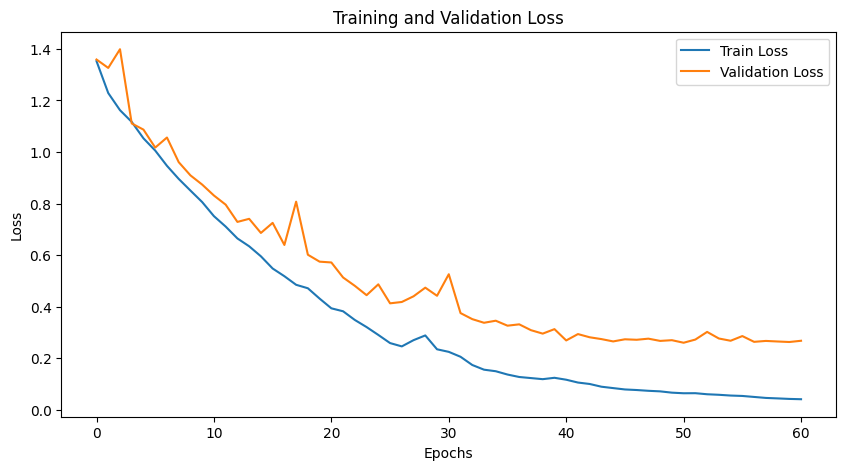

In [7]:
trainer.plot_losses()

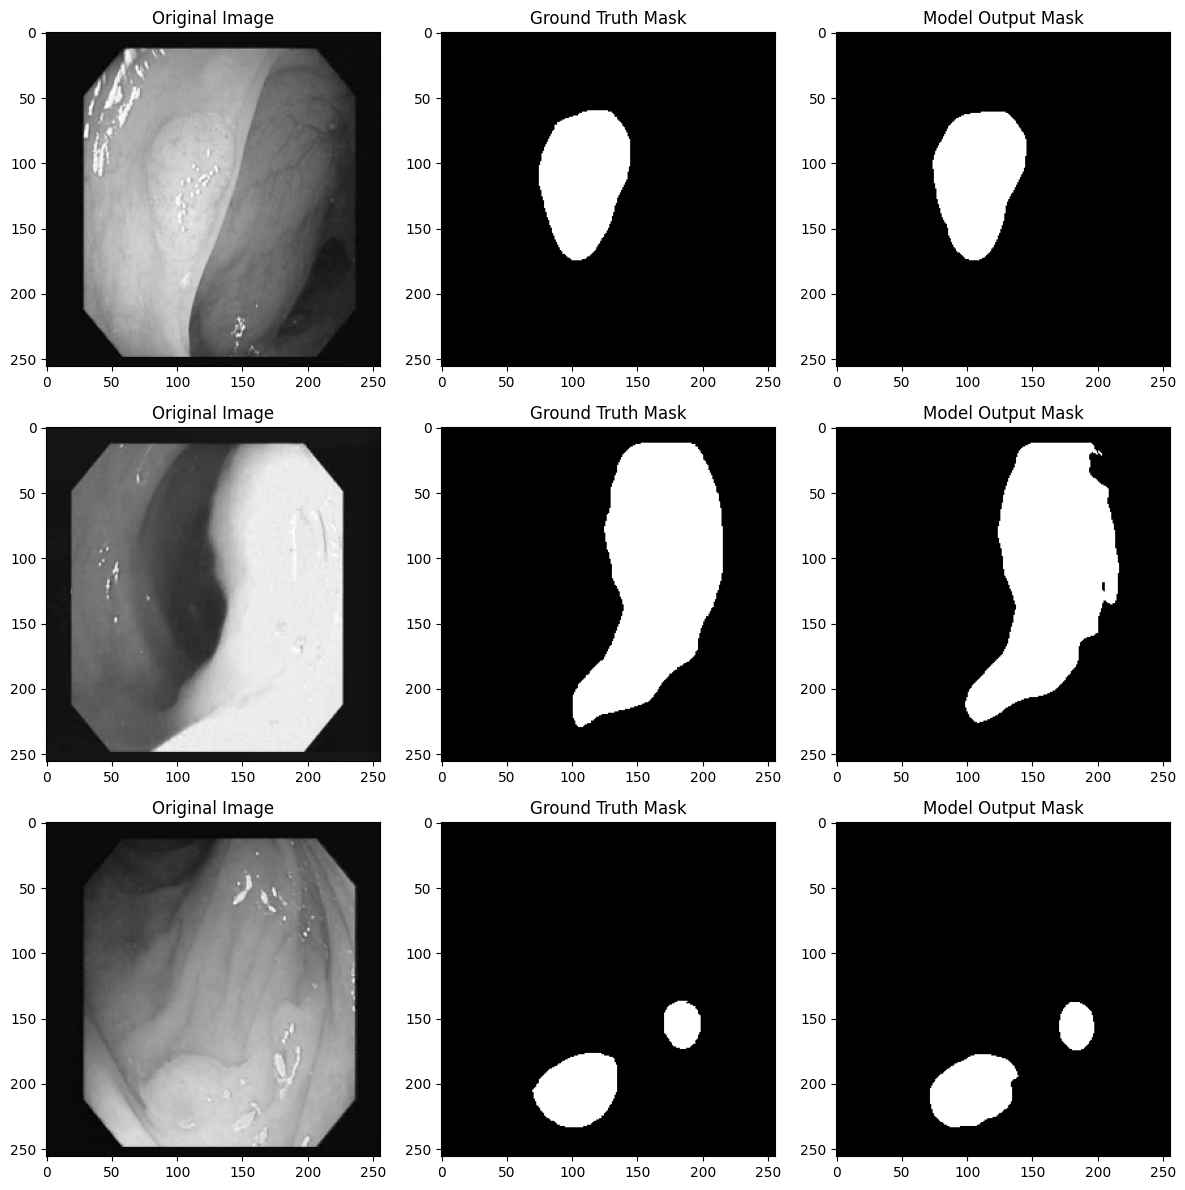

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:01<00:00,  6.87it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.2682
Average Dice Score                 : 0.8310
Average Hausdorff Distance         : inf
Average IoU                        : 0.7545
Precision                          : 0.9488
Recall                             : 0.8006
F1 Score                           : 0.8684
IoU (batch avg)                    : 0.7560
Dice (batch avg)                   : 0.8575
Total Parameters                   : 9,163,329
Trainable Parameters               : 9,163,329
Average Inference Time (seconds)   : 0.053738
FPS (Frames Per Second)            : 18.61
FLOPs                              : 34,903,425,024.0
GFLOPs                             : 34.9034

Results saved to: model_comparisons/evaluation_results/UNetPP_model_CVC-ClinicDB_evaluation_results_20250906_001311.csv
Validation results saved to model_comparisons/evaluation_results/UNetPP_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.26816846057772636,
 'avg_dice_score': 0.8310195246094715,
 'avg_hd_score': inf,
 'avg_iou': 0.7545101777244057,
 'precision': 0.9488454887600447,
 'recall': 0.8005784563625908,
 'f1': 0.8684290149748403,
 'iou_batch_avg': 0.7560240253806114,
 'dice_batch_avg': 0.8575039505958557,
 'total_params': 9163329,
 'trainable_params': 9163329,
 'avg_inference_time': 0.05373753547668457,
 'fps': 18.608966546928375,
 'flops': 34903425024.0,
 'gflops': 34.903425024}

# **Kvasir-SEG dataset**

In [10]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")


CUDA device found.


Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


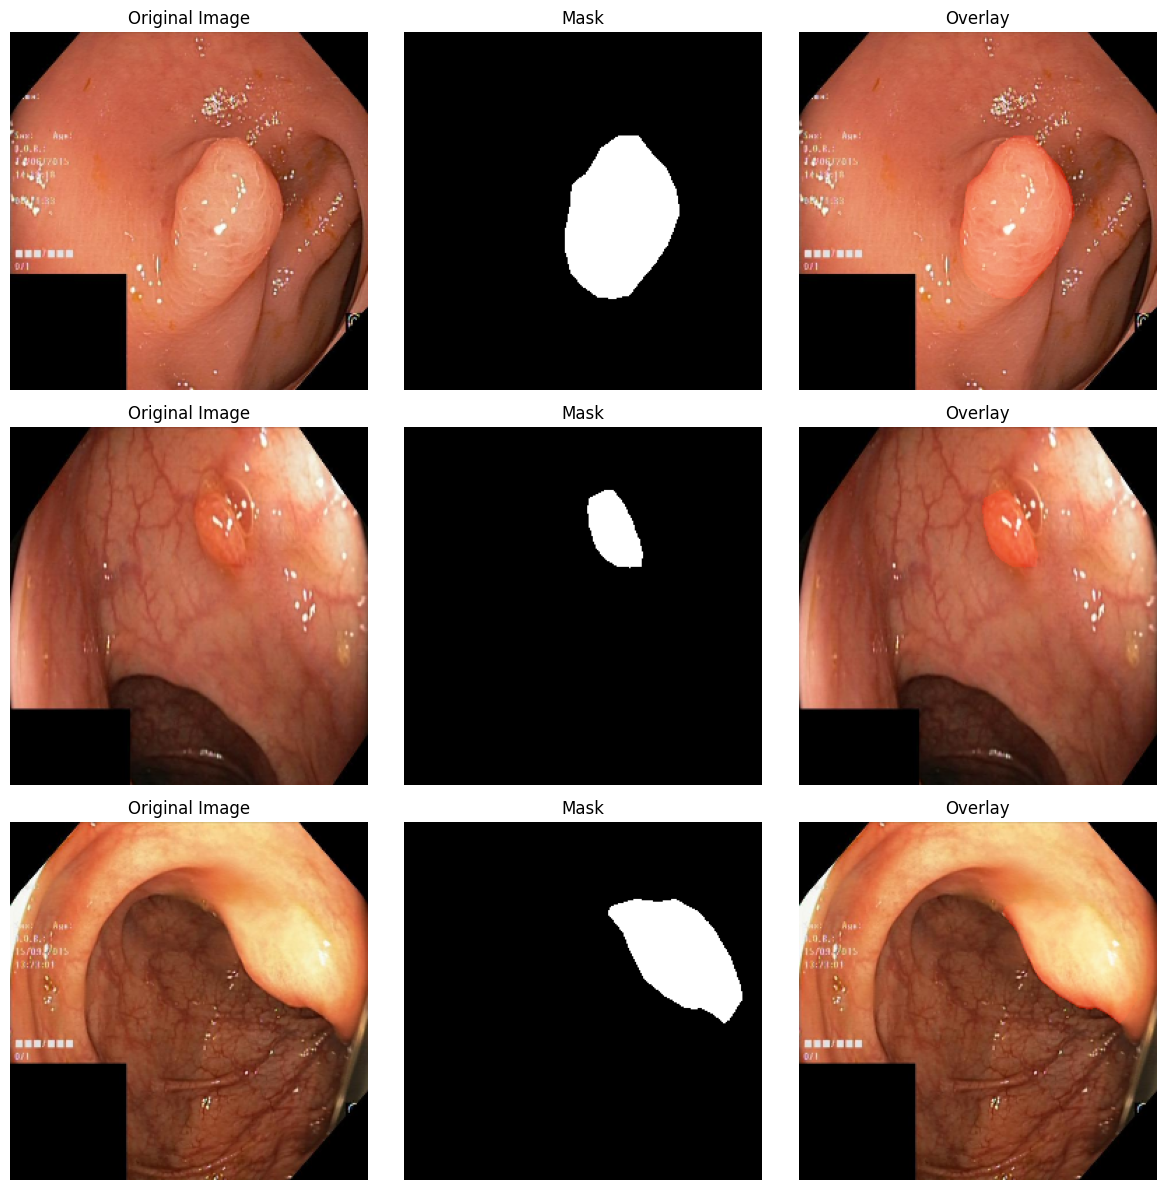

In [11]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

dataset.visualize_samples()

# UNet Kvasir training config

In [12]:
cfg = TrainConfig(
    # --- General ---
    model_name = "UNetPP",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [13]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [14]:
model = NestedUNet(num_classes=1, input_channels=3)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-06 00:30:17 | INFO | UNetPP_model_Kvasir_SEG_20250906_003017 | Logging to model_comparisons/logs/UNetPP_model_Kvasir_SEG_20250906_003017.log


2025-09-06 00:30:18 | INFO | UNetPP_model_Kvasir_SEG_20250906_003017 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/67ig0z5u
100%|██████████| 13/13 [00:05<00:00,  2.44it/s]
2025-09-06 00:30:46 | INFO | UNetPP_model_Kvasir_SEG_20250906_003017 | Epoch 001/100 | Train: 1.158284 | Val: 1.131177 | LR: 0.000100 | 28.67s | Val Dice: 0.5158 IoU: 0.3808 F1: 0.5459
2025-09-06 00:30:46 | INFO | UNetPP_model_Kvasir_SEG_20250906_003017 | Saved best: model_comparisons/models/best_UNetPP_model_Kvasir_SEG_20250906_003017.pth (val=1.131177)
100%|██████████| 13/13 [00:02<00:00,  4.71it/s]
2025-09-06 00:31:13 | INFO | UNetPP_model_Kvasir_SEG_20250906_003017 | Epoch 002/100 | Train: 1.023014 | Val: 0.980143 | LR: 0.000100 | 25.23s | Val Dice: 0.5773 IoU: 0.4445 F1: 0.6261
2025-09-06 00:31:13 | INFO | UNetPP_model_Kvasir_SEG_20250906_003017 | Saved best: model_comparisons/models/best_UNetPP_model_Kvasir_SEG_20250906_003017.pth (val=0.980143)
100%|██████████| 13/13 [00:03<00:00,  3.34i

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▅▅▂▄▅▆▃▃▃▂▄▄▆▅▆█▅▄█▇▇▃▃▄▁█▃▅▄▄▆▃▆▅▄▁▂
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▄▃▇▅▄▃▆▆▆▇▅▅▃▄▃▁▄▅▁▂▂▆▆▅█▁▆▄▅▅▃▆▃▄▅█▇
epoch_seconds,█▂▄▃▃▅▃▄▃▃▂▂▂▅▃▂▁▃▁▂▂▁▂▁▂▁▁▂▁▃▁▂▂▃▃▂▃
lr,████████████████████████████████▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▃▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇███████▇██████
train/f1,▁▂▃▃▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇███████▇██████
train/iou,▁▂▂▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇███▇▇▇██████
+11,...


{'best_val_loss': 0.3872438394106351,
 'epochs_ran': 37,
 'best_model_path': 'model_comparisons/models/best_UNetPP_model_Kvasir_SEG_20250906_003017.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_UNetPP_Kvasir_SEG_20250906_003017.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/67ig0z5u',
 'log_path': 'model_comparisons/logs/UNetPP_model_Kvasir_SEG_20250906_003017.log'}

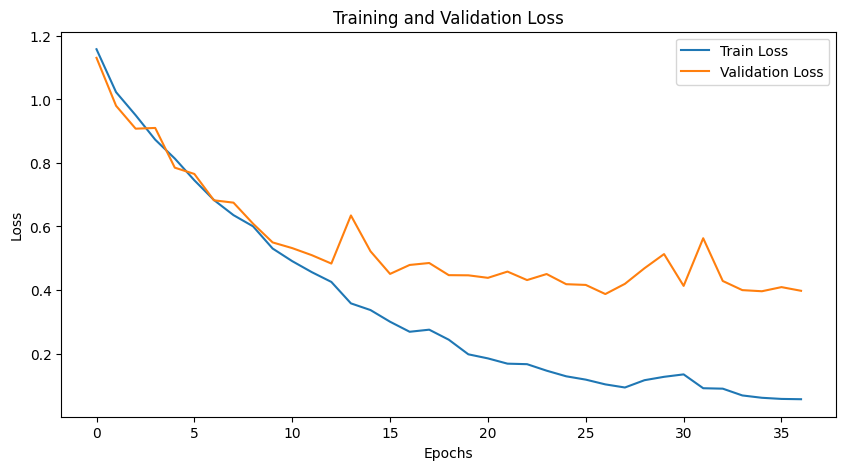

In [15]:
trainer.plot_losses()

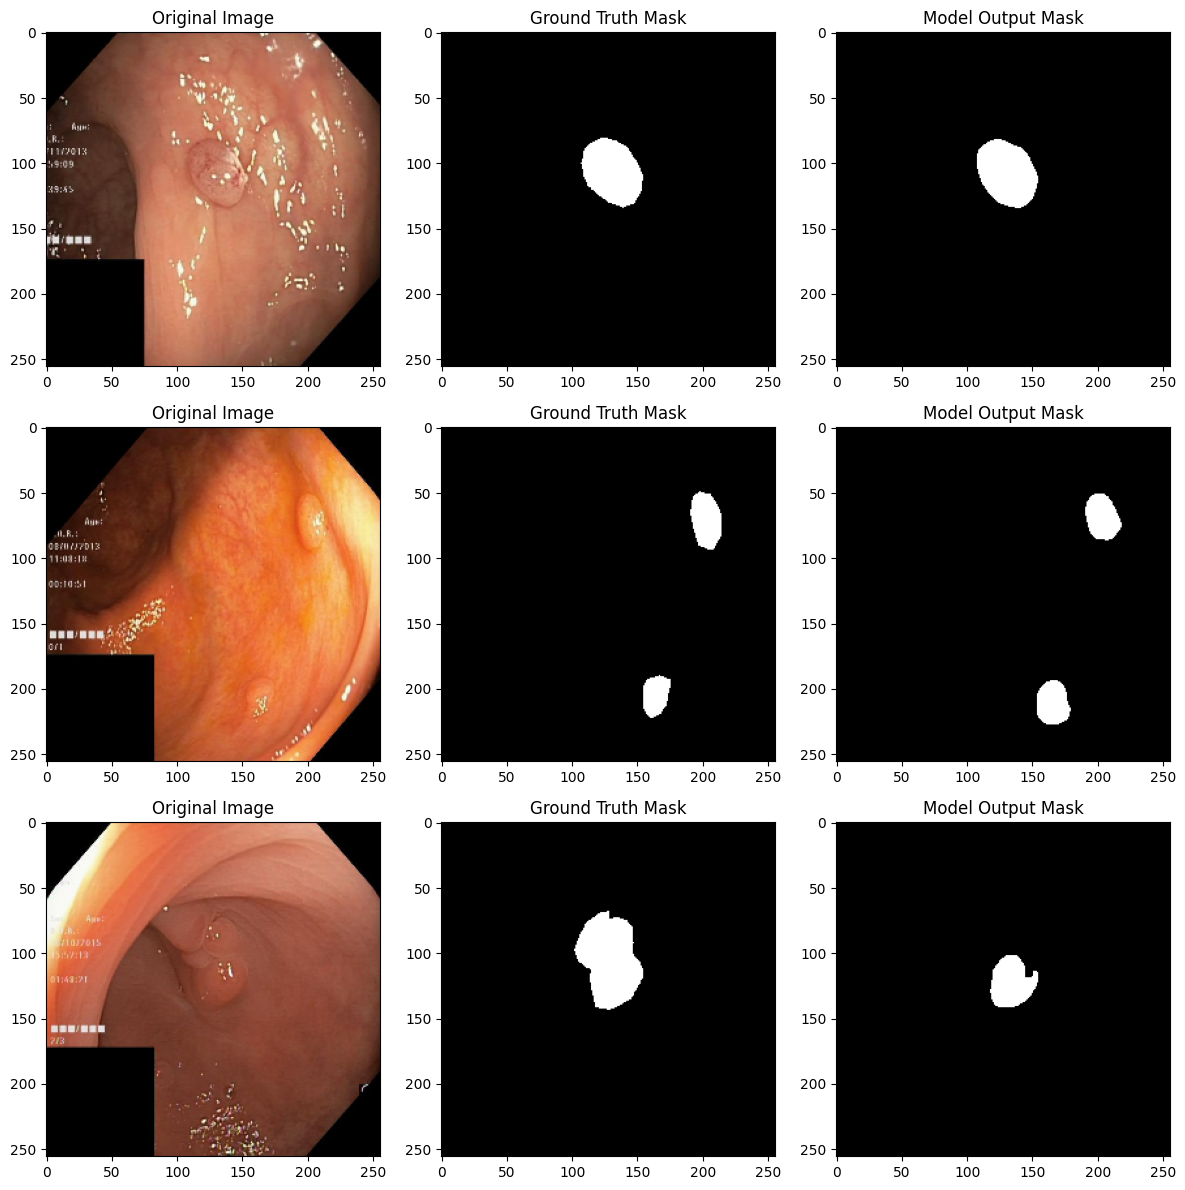

In [16]:
trainer.visualize_output_samples()

In [17]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:02<00:00,  4.85it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.3975
Average Dice Score                 : 0.8148
Average Hausdorff Distance         : inf
Average IoU                        : 0.7263
Precision                          : 0.8952
Recall                             : 0.7666
F1 Score                           : 0.8259
IoU (batch avg)                    : 0.7131
Dice (batch avg)                   : 0.8273
Total Parameters                   : 9,163,329
Trainable Parameters               : 9,163,329
Average Inference Time (seconds)   : 0.053361
FPS (Frames Per Second)            : 18.74
FLOPs                              : 34,903,425,024.0
GFLOPs                             : 34.9034

Results saved to: model_comparisons/evaluation_results/UNetPP_model_Kvasir-SEG_evaluation_results_20250906_003017.csv
Validation results saved to model_comparisons/evaluation_results/UNetPP_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.3975039216188284,
 'avg_dice_score': 0.8147643436036137,
 'avg_hd_score': inf,
 'avg_iou': 0.7262921368201327,
 'precision': 0.8952023822394367,
 'recall': 0.766578414827919,
 'f1': 0.8259125684185762,
 'iou_batch_avg': 0.7130932624523456,
 'dice_batch_avg': 0.8272544466532193,
 'total_params': 9163329,
 'trainable_params': 9163329,
 'avg_inference_time': 0.053361310958862304,
 'fps': 18.74016927303243,
 'flops': 34903425024.0,
 'gflops': 34.903425024}